# **Skripsi Refan Pakcoy**

**Install Package & Cek GPU**

In [38]:
!pip install -q ultralytics pyyaml opencv-python-headless scikit-learn pandas matplotlib joblib

import torch
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA tersedia: True
GPU: Tesla T4


**Import Library**

In [39]:
import os
import glob
import json
import shutil
import math
import yaml
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict, Counter
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


**Verifikasi Model Trained & Dataset Input**

In [40]:
# Model yang sudah pernah ditrain sebelumnya
PRETRAINED_MODEL_PATH = "/kaggle/input/models/refandinnufalah/best/pytorch/default/1/best.pt"
DATASET_INPUT_DIR = "/kaggle/input/datasets/refandinnufalah/pakcoy-yolov11-seg"

# Jika file model di direktori tersebut berupa format folder PyTorch ZIP (misal data.pkl)
if not os.path.exists(PRETRAINED_MODEL_PATH):
    # Coba cek apakah file model berada langsung di folder default/1
    alt_path = "/kaggle/input/models/refandinnufalah/best/pytorch/default/1"
    if os.path.exists(alt_path):
        PRETRAINED_MODEL_PATH = alt_path

print("Path Model Trained :", PRETRAINED_MODEL_PATH)
print("Path Dataset Input :", DATASET_INPUT_DIR)

assert os.path.exists(DATASET_INPUT_DIR), f"Dataset tidak ditemukan di {DATASET_INPUT_DIR}"

Path Model Trained : /kaggle/input/models/refandinnufalah/best/pytorch/default/1/best.pt
Path Dataset Input : /kaggle/input/datasets/refandinnufalah/pakcoy-yolov11-seg


**Konversi Dataset COCO JSON ke Format YOLO Segmentation**

In [41]:
OUTPUT_DIR = "/kaggle/working/dataset_pakcoy_yolo"

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Definisikan mapping kategori (COCO category_id -> YOLO class_id 0)
category_mapping = {
    1: 0,
    0: 0
}

# 2. Buat indeks gambar asli dari folder input Kaggle
image_index = defaultdict(list)
for root, dirs, files in os.walk(DATASET_INPUT_DIR):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            image_index[file].append(os.path.join(root, file))

# 3. Path anotasi COCO (Train, Valid, Test)
annotation_paths = {
    "train": os.path.join(DATASET_INPUT_DIR, "train/_annotations.coco.json"),
    "valid": os.path.join(DATASET_INPUT_DIR, "valid/_annotations.coco.json"),
    "test": os.path.join(DATASET_INPUT_DIR, "test/_annotations.coco.json")
}

split_mapping = {
    "train": "train",
    "valid": "valid",
    "val": "valid",
    "test": "test"
}

print("Memulai konversi anotasi COCO ke YOLO...")

for original_split, json_path in annotation_paths.items():
    split = split_mapping.get(original_split.lower())
    if not os.path.exists(json_path):
        print(f"File anotasi tidak ditemukan: {json_path}")
        continue

    print(f"\nMemproses split: {split}")
    with open(json_path, "r") as f:
        coco = json.load(f)

    images = {img["id"]: img for img in coco["images"]}
    annotations = defaultdict(list)
    for ann in coco["annotations"]:
        annotations[ann["image_id"]].append(ann)

    image_out = os.path.join(OUTPUT_DIR, "images", split)
    label_out = os.path.join(OUTPUT_DIR, "labels", split)
    os.makedirs(image_out, exist_ok=True)
    os.makedirs(label_out, exist_ok=True)

    copied_images = 0
    valid_polygons = 0

    for image_id, img in images.items():
        filename = Path(img["file_name"]).name
        candidates = image_index.get(filename, [])

        if not candidates:
            continue

        source_image = candidates[0]
        destination_image = os.path.join(image_out, filename)
        shutil.copy2(source_image, destination_image)
        copied_images += 1

        width = float(img["width"])
        height = float(img["height"])
        label_lines = []

        for ann in annotations.get(image_id, []):
            class_id = category_mapping.get(ann["category_id"])
            if class_id is None:
                continue

            segmentation = ann.get("segmentation", [])
            if not isinstance(segmentation, list) or len(segmentation) == 0:
                continue

            valid_candidates = []
            for polygon in segmentation:
                if not isinstance(polygon, list) or len(polygon) < 6 or len(polygon) % 2 != 0:
                    continue

                points = []
                for i in range(0, len(polygon), 2):
                    x = float(polygon[i]) / width
                    y = float(polygon[i + 1]) / height
                    if math.isfinite(x) and math.isfinite(y):
                        x = max(0.0, min(1.0, x))
                        y = max(0.0, min(1.0, y))
                        points.append((x, y))

                if len(points) >= 3:
                    valid_candidates.append(points)

            if not valid_candidates:
                continue

            def polygon_area(pts):
                area = 0.0
                n = len(pts)
                for i in range(n):
                    x1, y1 = pts[i]
                    x2, y2 = pts[(i + 1) % n]
                    area += x1 * y2 - x2 * y1
                return abs(area) / 2

            polygon_points = max(valid_candidates, key=polygon_area)
            coords = []
            for x, y in polygon_points:
                coords.extend([x, y])

            label_line = f"{class_id} " + " ".join(f"{v:.6f}" for v in coords)
            label_lines.append(label_line)
            valid_polygons += 1

        label_file = os.path.join(label_out, Path(filename).stem + ".txt")
        with open(label_file, "w") as f:
            f.write("\n".join(label_lines))

    print(f"Split {split} selesai | Gambar: {copied_images} | Polygon: {valid_polygons}")

print("\nKonversi dataset selesai!")

Memulai konversi anotasi COCO ke YOLO...

Memproses split: train
Split train selesai | Gambar: 886 | Polygon: 3678

Memproses split: valid
Split valid selesai | Gambar: 253 | Polygon: 1054

Memproses split: test
Split test selesai | Gambar: 127 | Polygon: 613

Konversi dataset selesai!


**Membuat File data.yaml**

In [42]:
DATA_YAML = os.path.join(OUTPUT_DIR, "data.yaml")

config = {
    "path": OUTPUT_DIR,
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "names": {
        0: "daun-pakcoy"
    }
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print("File data.yaml berhasil dibuat!")
print(open(DATA_YAML).read())

File data.yaml berhasil dibuat!
path: /kaggle/working/dataset_pakcoy_yolo
train: images/train
val: images/valid
test: images/test
names:
  0: daun-pakcoy



**Memuat Model Trained YOLOv11 Pakcoy**

In [43]:
print(f"Memuat model dari: {PRETRAINED_MODEL_PATH}")

model = YOLO(PRETRAINED_MODEL_PATH)

print("\nINFORMASI MODEL BERHASIL DIMUAT:")
print("Task       :", model.task)
print("Jumlah Kelas:", len(model.names))
print("Nama Kelas  :", model.names)

Memuat model dari: /kaggle/input/models/refandinnufalah/best/pytorch/default/1/best.pt

INFORMASI MODEL BERHASIL DIMUAT:
Task       : segment
Jumlah Kelas: 1
Nama Kelas  : {0: 'daun-pakcoy'}


**Evaluasi Model pada Data Validation (Val)**

In [44]:
print("=== MEMULAI EVALUASI DATA VALIDASI (VAL) ===")

val_metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/kaggle/working/hasil_evaluasi",
    name="val_pakcoy",
    exist_ok=True
)

print("\nHASIL METRIK VALIDATION:")
print(f"Box  - Precision : {val_metrics.box.mp:.4f}")
print(f"Box  - Recall    : {val_metrics.box.mr:.4f}")
print(f"Box  - mAP50     : {val_metrics.box.map50:.4f}")
print(f"Box  - mAP50-95  : {val_metrics.box.map:.4f}")
print(f"Mask - Precision : {val_metrics.seg.mp:.4f}")
print(f"Mask - Recall    : {val_metrics.seg.mr:.4f}")
print(f"Mask - mAP50     : {val_metrics.seg.map50:.4f}")
print(f"Mask - mAP50-95  : {val_metrics.seg.map:.4f}")

=== MEMULAI EVALUASI DATA VALIDASI (VAL) ===
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2179.0±1020.4 MB/s, size: 1220.7 KB)
val: Scanning /kaggle/working/dataset_pakcoy_yolo/labels/valid... 253 images, 57 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 253/253 493.8it/s 0.5s0.4s
val: /kaggle/working/dataset_pakcoy_yolo/images/valid/pakcoy5_day36 (1)_jpg.rf.0VDh2lVWE208flQFUeRz.jpg: corrupt JPEG restored and saved
val: /kaggle/working/dataset_pakcoy_yolo/images/valid/pakcoy7_day25 (5)_jpg.rf.Q8IGfhqO4AP5kS4hJCyq.jpg: corrupt JPEG restored and saved
val: New cache created: /kaggle/working/dataset_pakcoy_yolo/labels/valid.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.4it/s 13.5s0.5s
                  

**Evaluasi Model pada Data Testing & Simpan Laporan (CSV/Excel)**

In [45]:
EVAL_OUT_DIR = "/kaggle/working/hasil_evaluasi_skripsi"
os.makedirs(EVAL_OUT_DIR, exist_ok=True)

print("=== MEMULAI EVALUASI DATA TESTING (TEST) ===")

test_metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    conf=0.001,
    iou=0.6,
    plots=True,
    save_json=True,
    project=EVAL_OUT_DIR,
    name="evaluasi_test",
    exist_ok=True
)

hasil = {
    "Precision (Box)": test_metrics.box.mp,
    "Recall (Box)": test_metrics.box.mr,
    "mAP50 (Box)": test_metrics.box.map50,
    "mAP50-95 (Box)": test_metrics.box.map,
    "Precision (Mask)": test_metrics.seg.mp,
    "Recall (Mask)": test_metrics.seg.mr,
    "mAP50 (Mask)": test_metrics.seg.map50,
    "mAP50-95 (Mask)": test_metrics.seg.map,
}

# Tampilkan Tabel Hasil
df_hasil = pd.DataFrame({
    "No": range(1, len(hasil) + 1),
    "Parameter Evaluasi": list(hasil.keys()),
    "Nilai": list(hasil.values()),
    "Persentase (%)": [v * 100 for v in hasil.values()]
})

print("\n" + "=" * 55)
print("             TABEL HASIL EVALUASI TEST")
print("=" * 55)
print(df_hasil.to_string(index=False, formatters={
    "Nilai": "{:.4f}".format,
    "Persentase (%)": "{:.2f}%".format
}))

# Simpan ke CSV & Excel
csv_path = os.path.join(EVAL_OUT_DIR, "hasil_evaluasi_yolo11n_seg.csv")
excel_path = os.path.join(EVAL_OUT_DIR, "hasil_evaluasi_yolo11n_seg.xlsx")

df_hasil.to_csv(csv_path, index=False)
df_hasil.to_excel(excel_path, index=False)

print(f"\nLaporan berhasil disimpan di:\n- {csv_path}\n- {excel_path}")

=== MEMULAI EVALUASI DATA TESTING (TEST) ===
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4964.9±1875.5 MB/s, size: 2243.7 KB)
val: Scanning /kaggle/working/dataset_pakcoy_yolo/labels/test... 127 images, 20 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 801.9it/s 0.2ss
val: New cache created: /kaggle/working/dataset_pakcoy_yolo/labels/test.cache
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 1.05s
Prepared 1 package in 299ms
Installed 1 package in 2ms
 + faster-coco-eval==1.8.0

requirements: AutoUpdate success ✅ 1.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)   

**Prediksi & Visualisasi Gambar Sampel Test**


image 1/1 /kaggle/working/dataset_pakcoy_yolo/images/test/pakcoy1_day38 (1)_jpg.rf.phGWNqw3ErfRrPTHz3SY.jpg: 640x480 7 daun-pakcoys, 13.3ms
Speed: 4.5ms preprocess, 13.3ms inference, 17.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /kaggle/working/prediction/pakcoy_test


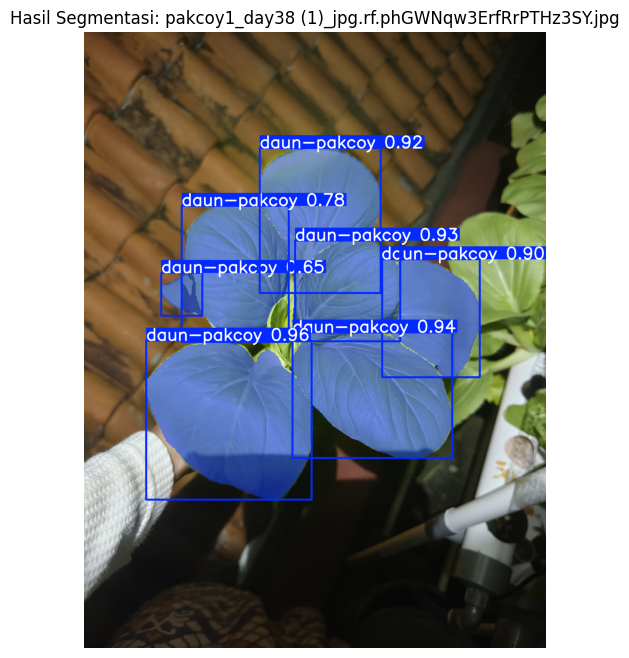

In [46]:
TEST_IMAGE_DIR = os.path.join(OUTPUT_DIR, "images/test")
test_images = glob.glob(os.path.join(TEST_IMAGE_DIR, "*.jpg")) + glob.glob(os.path.join(TEST_IMAGE_DIR, "*.png"))

if test_images:
    sample_img = test_images[0]
    
    # Jalankan Prediksi
    results = model.predict(
        source=sample_img,
        conf=0.25,
        imgsz=640,
        save=True,
        project="/kaggle/working/prediction",
        name="pakcoy_test",
        exist_ok=True
    )
    
    # Visualisasi Prediksi di Notebook
    res_img = results[0].plot()
    res_img = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(res_img)
    plt.title(f"Hasil Segmentasi: {Path(sample_img).name}")
    plt.axis("off")
    plt.show()
else:
    print("Tidak ada gambar test untuk diuji.")